# Practice Notebook 1: Descriptive Statistics, Probability, and Distributions

This practice notebook has two parts:

1. **Paper and pencil:** short questions that apply the lecture definitions and formulas.
2. **Python and interpretation:** three questions using brain-science examples.

For Part 1, write the reasoning as well as the final answer. For Part 2, run each cell and answer the interpretation questions before changing the code.

## Learning goals

By the end of the session, you should be able to:

- classify variables and choose suitable summary statistics
- detect outliers with the IQR rule and judge how robust each summary is
- quantify distribution shape with skewness, kurtosis, and normality tests
- apply conditional probability, independence, and Bayes' rule
- select, compute, and check discrete and continuous distributions


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)


# Part 1: Paper-and-pencil questions

Complete these questions without Python. You can use the calculator.


## 1. Study terminology and variable types

A lab records, for 25 adult rats of one laboratory strain, the number of lever presses in a 10-minute session, the time until the first lever press (seconds), the housing cage (A, B, or C), and an observer's anxiety rating (low, medium, high). The research question concerns all adult rats of this strain.

1. Identify the observational unit, the population, and the sample.
2. Give one example of a **value** in this study.
3. Classify each variable as precisely as possible and name a suitable summary metric:
   - number of lever presses
   - time until the first press
   - housing cage
   - anxiety rating
4. A student codes the anxiety rating as 1, 2, 3 and reports a mean of 2.1. What assumption does this summary make?


### Solution

1. **Observational unit:** one rat. **Population:** all adult rats of this strain. **Sample:** the 25 rats actually observed.

2. A value is one recorded outcome for one unit, for example "rat 7 pressed the lever 23 times".

3. **Variable types and metrics:**
   - Lever presses: numerical, discrete (a count). Summarize with the mean or the full distribution.
   - Time until first press: numerical, continuous. Summarize with mean, spread, and shape. Latencies are usually right-skewed, so the median and IQR are also useful.
   - Housing cage: categorical, nominal (three unordered levels). Summarize with counts and proportions.
   - Anxiety rating: categorical, ordinal (ordered levels). Summarize with ordered counts and the median.

4. A mean of ordinal codes assumes that the distance between "low" and "medium" equals the distance between "medium" and "high". Ordinal data only guarantee an order, so the median is the safer summary.


## 2. Descriptive statistics, robustness, and the boxplot rule

The times until the first lever press (seconds) for eight rats are:

$$
4,\ 7,\ 5,\ 6,\ 9,\ 5,\ 8,\ 36
$$

1. Calculate the mean, median, mode, and range.
2. Calculate the sample variance and sample standard deviation.
3. Using the median-of-halves method (Q1 is the median of the lower four values, Q3 the median of the upper four values), find Q1, Q3, and the IQR.
4. Calculate the boxplot fences $Q1-1.5\cdot IQR$ and $Q3+1.5\cdot IQR$. Which observations are outliers?
5. Recalculate the mean, median, and standard deviation without the value 36. Which summaries changed most?
6. Should the value 36 simply be deleted? Which summaries would you report for these data?


### Solution

1. The sum is 80, so

$$
\bar x=\frac{80}{8}=10\text{ s}.
$$

The ordered values are 4, 5, 5, 6, 7, 8, 9, 36. With an even number of values, the median is the average of the two middle values:

$$
\text{median}=\frac{6+7}{2}=6.5\text{ s}.
$$

The mode is 5 s (it occurs twice). The range is $36-4=32$ s.

2. The deviations from the mean are $-6,-3,-5,-4,-1,-5,-2,26$. Their squares sum to

$$
36+9+25+16+1+25+4+676=792,
$$

$$
s^2=\frac{792}{8-1}\approx113.14,\qquad s=\sqrt{113.14}\approx10.64\text{ s}.
$$

3. Lower half: 4, 5, 5, 6, so $Q1=5$. Upper half: 7, 8, 9, 36, so $Q3=8.5$. Therefore $IQR=8.5-5=3.5$ s.

4. The fences are

$$
Q1-1.5\cdot IQR=5-5.25=-0.25,\qquad Q3+1.5\cdot IQR=8.5+5.25=13.75.
$$

Only 36 s lies outside the fences, so it is the only outlier.

5. Without 36: $\bar x=44/7\approx6.29$ s, median $=6$ s, $s\approx1.80$ s. The mean dropped by 3.71 s and the standard deviation dropped from 10.64 to 1.80 s, while the median moved by only 0.5 s. The mean, SD, and range are sensitive to the single extreme value; the median and IQR are robust.

6. Not automatically. First check whether 36 s is a recording error. A genuinely slow rat is real data, and deleting it would bias the results. A defensible choice is to report the **median and IQR**, or to report the analysis with and without the value.


## 3. Distribution shape

Use the kurtosis formula

$$
\text{Kurtosis}=\frac{\frac{1}{n}\sum(x_i-\bar x)^4}{\left[\frac{1}{n}\sum(x_i-\bar x)^2\right]^2}.
$$

Dataset A: $1,2,3,4,5$

Dataset B: $0,0,0,0,0,0,0,0,-4,4$

1. Calculate the kurtosis of each dataset.
2. Classify each dataset as leptokurtic, platykurtic, or approximately normal.
3. A histogram of reaction times has a long tail towards slow responses. Name the type of skew and predict whether the mean or the median is larger.
4. Name two formal normality tests. What does a small p-value mean in such a test?


### Solution

1. **Dataset A:** $\bar x=3$, deviations $-2,-1,0,1,2$.

$$
\frac{1}{5}\sum(x_i-\bar x)^2=\frac{10}{5}=2,\qquad
\frac{1}{5}\sum(x_i-\bar x)^4=\frac{34}{5}=6.8,\qquad
\text{Kurtosis}=\frac{6.8}{2^2}=1.7.
$$

**Dataset B:** $\bar x=0$.

$$
\frac{1}{10}\sum x_i^2=\frac{32}{10}=3.2,\qquad
\frac{1}{10}\sum x_i^4=\frac{512}{10}=51.2,\qquad
\text{Kurtosis}=\frac{51.2}{3.2^2}=\frac{51.2}{10.24}=5.0.
$$

2. Dataset A: $1.7<3$, platykurtic (flat, light tails). Dataset B: $5.0>3$, leptokurtic (most values in a sharp peak, a few extreme values in heavy tails).

3. A long tail to the right is **positive (right) skew**. The few very slow responses pull the mean upward, so typically mean > median.

4. **Shapiro-Wilk** and **Kolmogorov-Smirnov**. Their null hypothesis is that the data come from a normal distribution, so a small p-value is evidence against normality.


## 4. Conditional probability and Bayes' rule

An algorithm flags EEG epochs as containing a seizure. Let $S$ denote "the epoch contains a seizure" and $A$ "the algorithm raises an alarm":

$$
P(S)=0.02,\qquad P(A\mid S)=0.95,\qquad P(A\mid S^c)=0.10.
$$

1. Calculate $P(S\cap A)$ with the product rule.
2. Calculate $P(A)$ by adding up the two ways an alarm can occur.
3. Calculate $P(S\mid A)$ with Bayes' rule and interpret it.
4. Name the prior, the likelihood, and the normalisation in your Bayes calculation.
5. Calculate $P(S\cup A)$.
6. Are $S$ and $A$ independent? Are they mutually exclusive? Show the numbers you use.
7. Explain why $P(A\mid S)=0.95$ is so different from $P(S\mid A)$.


### Solution

1. Product rule:

$$
P(S\cap A)=P(A\mid S)P(S)=0.95(0.02)=0.019.
$$

2. An alarm occurs either with a seizure or as a false alarm:

$$
P(A)=P(A\mid S)P(S)+P(A\mid S^c)P(S^c)=0.019+0.10(0.98)=0.019+0.098=0.117.
$$

3. Bayes' rule:

$$
P(S\mid A)=\frac{P(A\mid S)P(S)}{P(A)}=\frac{0.019}{0.117}\approx0.162.
$$

Only about 16% of alarms correspond to real seizures.

4. Prior: $P(S)=0.02$. Likelihood: $P(A\mid S)=0.95$. Normalisation: $P(A)=0.117$, summed over both explanations of an alarm (seizure and no seizure).

5. Addition rule:

$$
P(S\cup A)=0.02+0.117-0.019=0.118.
$$

6. **Not independent:** $P(A\mid S)=0.95\neq P(A)=0.117$. Equivalently, $P(S)P(A)=0.00234\neq P(S\cap A)=0.019$. **Not mutually exclusive:** $P(S\cap A)=0.019>0$; an epoch can contain a seizure and an alarm.

7. The two probabilities condition on different reference groups. $P(A\mid S)$ looks only at seizure epochs. $P(S\mid A)$ looks at alarm epochs, and most of these come from the 98% of epochs without a seizure: false alarms contribute 0.098 to $P(A)$, true alarms only 0.019. A low prior makes even a sensitive test produce mostly false alarms.


## 5. Choosing and using distributions

For each situation, name the distribution and its parameter(s), then calculate the requested quantities.

1. A participant views 10 faces. Each face is recognized correctly with probability 0.7, independently. Find $P(X=8)$, $P(X=10)$, $E(X)$, and $\operatorname{Var}(X)$.
2. A neuron fires at a constant rate of 5 spikes per second. Let $Y$ be the spike count in a 0.4 s window. Find $P(Y=0)$, $P(Y\ge1)$, $E(Y)$, and $\operatorname{Var}(Y)$.
3. Let $T$ be the waiting time until the next spike of the same neuron. Find $E(T)$, $\operatorname{Var}(T)$, and $P(T>0.4)$ using $P(T>t)=e^{-\lambda t}$. Why does $P(T>0.4)$ equal $P(Y=0)$?
4. Stimulus onset is jittered uniformly between 200 and 600 ms. Find the density height, the mean, the standard deviation, and $P(300\le X\le350)$.
5. IQ scores follow $N(100,15^2)$. Using $P(Z>2)\approx0.023$, find $P(\text{IQ}>130)$.


### Solution

1. **Binomial** with $n=10$, $p=0.7$:

$$
P(X=8)=\binom{10}{8}0.7^8\,0.3^2=45(0.05765)(0.09)\approx0.2335,\qquad P(X=10)=0.7^{10}\approx0.0282,
$$

$$
E(X)=np=7,\qquad \operatorname{Var}(X)=np(1-p)=10(0.7)(0.3)=2.1.
$$

2. **Poisson** with $\lambda=5\times0.4=2$ expected spikes per window:

$$
P(Y=0)=\frac{2^0e^{-2}}{0!}=e^{-2}\approx0.1353,\qquad P(Y\ge1)=1-e^{-2}\approx0.8647,\qquad E(Y)=\operatorname{Var}(Y)=2.
$$

3. **Exponential** with rate $\lambda=5$ per second:

$$
E(T)=\frac{1}{\lambda}=0.2\text{ s},\qquad \operatorname{Var}(T)=\frac{1}{\lambda^2}=0.04\text{ s}^2,\qquad P(T>0.4)=e^{-5(0.4)}=e^{-2}\approx0.1353.
$$

Waiting longer than 0.4 s for the next spike is the same event as observing zero spikes in the next 0.4 s, so the Poisson and exponential models give the same probability.

4. **Continuous uniform** $U(200,600)$:

$$
f(x)=\frac{1}{600-200}=0.0025\text{ per ms},\qquad E(X)=\frac{200+600}{2}=400\text{ ms},
$$

$$
\operatorname{Var}(X)=\frac{(600-200)^2}{12}\approx13333\text{ ms}^2,\qquad SD\approx115.5\text{ ms},\qquad P(300\le X\le350)=\frac{50}{400}=0.125.
$$

5. **Normal:** $z=\dfrac{130-100}{15}=2$, so $P(\text{IQ}>130)=P(Z>2)\approx0.023$.


## 6. Probability mass vs. probability density

1. Is $p(0)=0.2,\ p(1)=0.5,\ p(2)=0.4$ a valid probability mass function? Explain.
2. Let $f(x)=3x^2$ for $0\le x\le1$ and $f(x)=0$ otherwise. Is $f$ a valid density? Calculate $P(X\le0.5)$ and $P(X=0.5)$.
3. Which of the following needs a PMF and which a PDF: the number of spikes in a window, the interval between two spikes?


### Solution

1. No. Each value lies between 0 and 1, but the probabilities must sum to 1, and here $0.2+0.5+0.4=1.1$.

2. Yes. $f(x)\ge0$ everywhere and

$$
\int_0^1 3x^2\,dx=\left[x^3\right]_0^1=1.
$$

Then

$$
P(X\le0.5)=\int_0^{0.5}3x^2\,dx=0.5^3=0.125.
$$

$P(X=0.5)=0$, because a single point has zero area under a density.

3. The spike count is discrete, so it has a PMF. The inter-spike interval is continuous, so it has a PDF.


# Part 2: Python and interpretation

The code is complete and runnable. Your task is to inspect the output, connect it to the lecture, and make small changes when requested.


## Q1: Describing shape, outliers, and normality

Reaction times are usually right-skewed. We simulate 200 skewed reaction times (log-normal) and 200 roughly normal reaction times, then compute descriptive statistics, the kurtosis formula from the lecture, the number of IQR-rule outliers, and the Shapiro-Wilk p-value.


                    skewed RTs    normal RTs
mean                   450.085       473.640
median                 429.875       475.618
SD                     139.518        77.812
IQR                    175.731       103.745
skewness                 0.807        -0.128
kurtosis                 3.765         3.014
IQR outliers             3.000         1.000
Shapiro-Wilk p           0.000         0.612


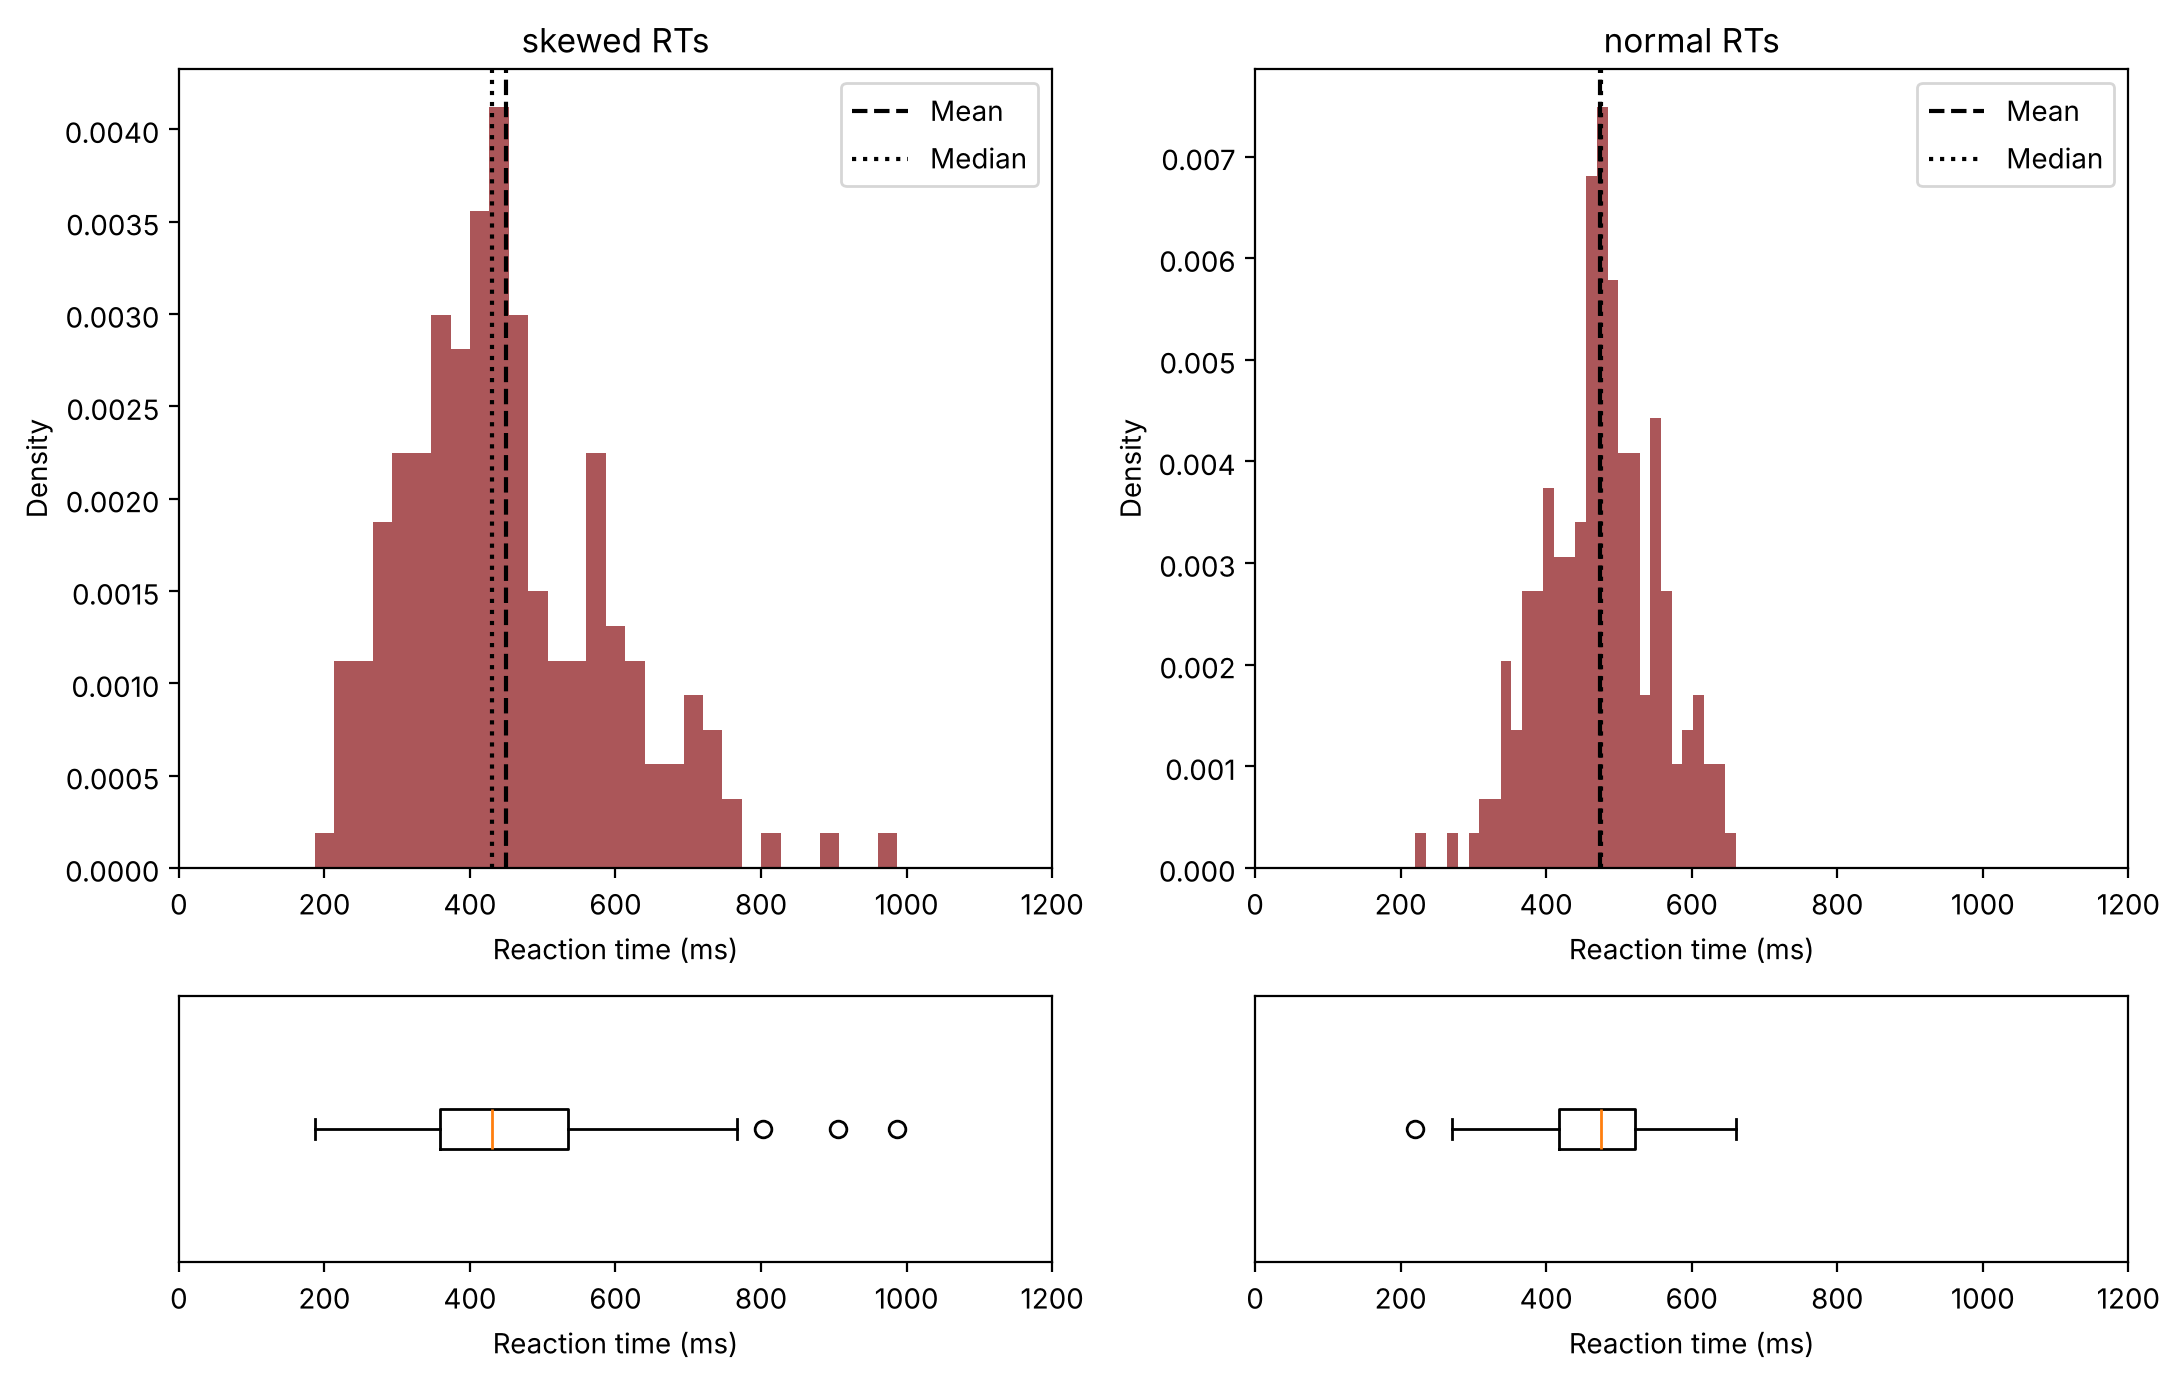

In [2]:
rng = np.random.default_rng(7)
n = 200

rt_skewed = rng.lognormal(mean=np.log(450), sigma=0.35, size=n)
rt_normal = rng.normal(loc=480, scale=80, size=n)


def describe(x):
    mean = x.mean()
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    kurtosis = np.mean((x - mean) ** 4) / np.mean((x - mean) ** 2) ** 2
    n_outliers = np.sum((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr))
    shapiro_p = stats.shapiro(x).pvalue
    return {
        "mean": mean,
        "median": np.median(x),
        "SD": x.std(ddof=1),
        "IQR": iqr,
        "skewness": stats.skew(x),
        "kurtosis": kurtosis,
        "IQR outliers": n_outliers,
        "Shapiro-Wilk p": shapiro_p,
    }


summaries = {"skewed RTs": describe(rt_skewed), "normal RTs": describe(rt_normal)}

print(f"{'':16}{'skewed RTs':>14}{'normal RTs':>14}")
for key in summaries["skewed RTs"]:
    a, b = summaries["skewed RTs"][key], summaries["normal RTs"][key]
    print(f"{key:16}{a:14.3f}{b:14.3f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), gridspec_kw={"height_ratios": [3, 1]})
for col, (name, x) in enumerate([("skewed RTs", rt_skewed), ("normal RTs", rt_normal)]):
    ax = axes[0, col]
    ax.hist(x, bins=30, density=True, color="#8f1d21", alpha=0.75)
    ax.axvline(x.mean(), color="black", linestyle="--", label="Mean")
    ax.axvline(np.median(x), color="black", linestyle=":", label="Median")
    ax.set_title(name)
    ax.set_xlabel("Reaction time (ms)")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 1200)
    ax.legend()

    axes[1, col].boxplot(x, orientation="horizontal", whis=1.5)
    axes[1, col].set_xlim(0, 1200)
    axes[1, col].set_yticks([])
    axes[1, col].set_xlabel("Reaction time (ms)")

plt.tight_layout()
plt.show()


### Interpretation questions

1. In which dataset is the mean clearly larger than the median? Why?
2. Interpret the sign and size of the skewness for each dataset.
3. Compare each kurtosis with 3. What do you conclude?
4. What is the null hypothesis of the Shapiro-Wilk test? What do you conclude for each dataset?
5. The IQR rule flags a few observations in each dataset. Should they be removed?
6. Change `n` from 200 to 20 and rerun. What happens to the Shapiro-Wilk p-value of the skewed data, and what does this say about non-significant normality tests?


### Model interpretation

1. In the skewed data the mean (about 450 ms) exceeds the median (about 430 ms). The long tail of slow responses pulls the mean upward, while the median is robust to extremes. In the normal data mean and median are almost equal (about 474 vs. 476 ms).

2. The skewed data have skewness of about 0.81, a clear positive (right) skew. The normal data have skewness of about $-0.13$, close to 0, so they are roughly symmetric.

3. The skewed data have kurtosis of about 3.77 (> 3), so they are somewhat leptokurtic with a heavier right tail. The normal data have kurtosis of about 3.01, as expected for a normal distribution.

4. $H_0$: the data come from a normal distribution. For the skewed data $p<0.001$, so normality is rejected. For the normal data $p\approx0.61$, so there is no evidence against normality. This does not prove that the data are normal.

5. Not automatically. In skewed data, very slow responses are an expected part of the distribution rather than errors. With $n=200$, one flagged point in normal data is also expected by chance. Remove observations only for justified, preferably pre-specified reasons (for example, recording errors). Otherwise, use robust summaries such as the median and IQR.

6. With $n=20$, the Shapiro-Wilk p-value for the skewed data rises to about 0.57, even though the population is clearly skewed. Small samples give normality tests little power, so a non-significant test is not evidence of normality. Very large samples have the opposite problem: they flag trivial deviations. Always inspect histograms or boxplots as well.


## Q2: Bayes' rule by simulation

We simulate 200,000 EEG epochs for the seizure detector from Part 1, Question 4, and estimate the conditional probabilities directly by counting. The simulation is repeated for three base rates (prior probabilities of a seizure).


In [3]:
rng = np.random.default_rng(11)


def simulate_detector(base_rate, sensitivity=0.95, false_alarm=0.10, n_epochs=200_000):
    seizure = rng.random(n_epochs) < base_rate
    u = rng.random(n_epochs)
    alarm = np.where(seizure, u < sensitivity, u < false_alarm)

    simulated = {
        "P(A)": alarm.mean(),
        "P(A|S)": alarm[seizure].mean(),
        "P(S|A)": seizure[alarm].mean(),
    }
    p_alarm = sensitivity * base_rate + false_alarm * (1 - base_rate)
    exact = {
        "P(A)": p_alarm,
        "P(A|S)": sensitivity,
        "P(S|A)": sensitivity * base_rate / p_alarm,
    }
    return simulated, exact


for base_rate in [0.02, 0.20, 0.50]:
    simulated, exact = simulate_detector(base_rate)
    print(f"Base rate P(S) = {base_rate:.2f}")
    for key in simulated:
        print(f"  {key:7} simulated = {simulated[key]:.3f}   Bayes' rule = {exact[key]:.3f}")


Base rate P(S) = 0.02
  P(A)    simulated = 0.117   Bayes' rule = 0.117
  P(A|S)  simulated = 0.954   Bayes' rule = 0.950
  P(S|A)  simulated = 0.161   Bayes' rule = 0.162
Base rate P(S) = 0.20
  P(A)    simulated = 0.272   Bayes' rule = 0.270
  P(A|S)  simulated = 0.950   Bayes' rule = 0.950
  P(S|A)  simulated = 0.703   Bayes' rule = 0.704
Base rate P(S) = 0.50
  P(A)    simulated = 0.525   Bayes' rule = 0.525
  P(A|S)  simulated = 0.950   Bayes' rule = 0.950
  P(S|A)  simulated = 0.905   Bayes' rule = 0.905


### Interpretation questions

1. Compare the simulated $P(S\mid A)$ for a base rate of 0.02 with your answer to Part 1, Question 4.
2. Which conditional probability stays the same across base rates? Why?
3. How does $P(S\mid A)$ change as the base rate increases? Which part of Bayes' rule changes?
4. A clinic needs $P(S\mid A)\ge0.5$ at a base rate of 0.02. Would raising the sensitivity to 1.0 be enough? Which detector property must improve instead?
5. Why are the simulated values not exactly equal to the Bayes' rule values?


### Model interpretation

1. The simulation gives $P(S\mid A)\approx0.161$, matching the hand calculation $0.019/0.117\approx0.162$.

2. $P(A\mid S)\approx0.95$ at every base rate. It is a property of the detector (its sensitivity) and conditions only on seizure epochs, so it does not depend on how common seizures are.

3. $P(S\mid A)$ rises from about 0.16 (base rate 0.02) to 0.70 (0.20) and 0.90 (0.50). The **prior** $P(S)$ changes. A larger prior increases true alarms relative to false alarms in the normalisation $P(A)$.

4. No. With sensitivity 1.0, $P(S\mid A)=0.02/(0.02+0.10\cdot0.98)\approx0.17$. False alarms dominate, so the false-alarm rate must drop. Solving $0.019/(0.019+f\cdot0.98)\ge0.5$ gives $f\le0.019$, about 1.9% instead of 10%.

5. Each run uses a finite random sample of epochs, so the estimates contain Monte Carlo variability. More epochs would bring them closer to the exact values.


## Q3: Poisson spike counts and exponential inter-spike intervals

We simulate a neuron firing at a constant rate of 5 spikes per second for 2000 s by drawing exponential inter-spike intervals (ISIs). We then count spikes in 0.4 s windows. Finally, we simulate a "bursty" neuron whose rate changes from window to window.


Mean ISI = 0.1982 s   (theory 1/rate = 0.2000)
Var ISI  = 0.0386 s^2 (theory 1/rate^2 = 0.0400)
Counts: mean = 2.017, variance = 2.042, variance/mean = 1.01
Proportion of empty windows = 0.128 (theory e^-2 = 0.135)
Bursty counts: mean = 2.070, variance = 6.106, variance/mean = 2.95
Bursty proportion of empty windows = 0.321


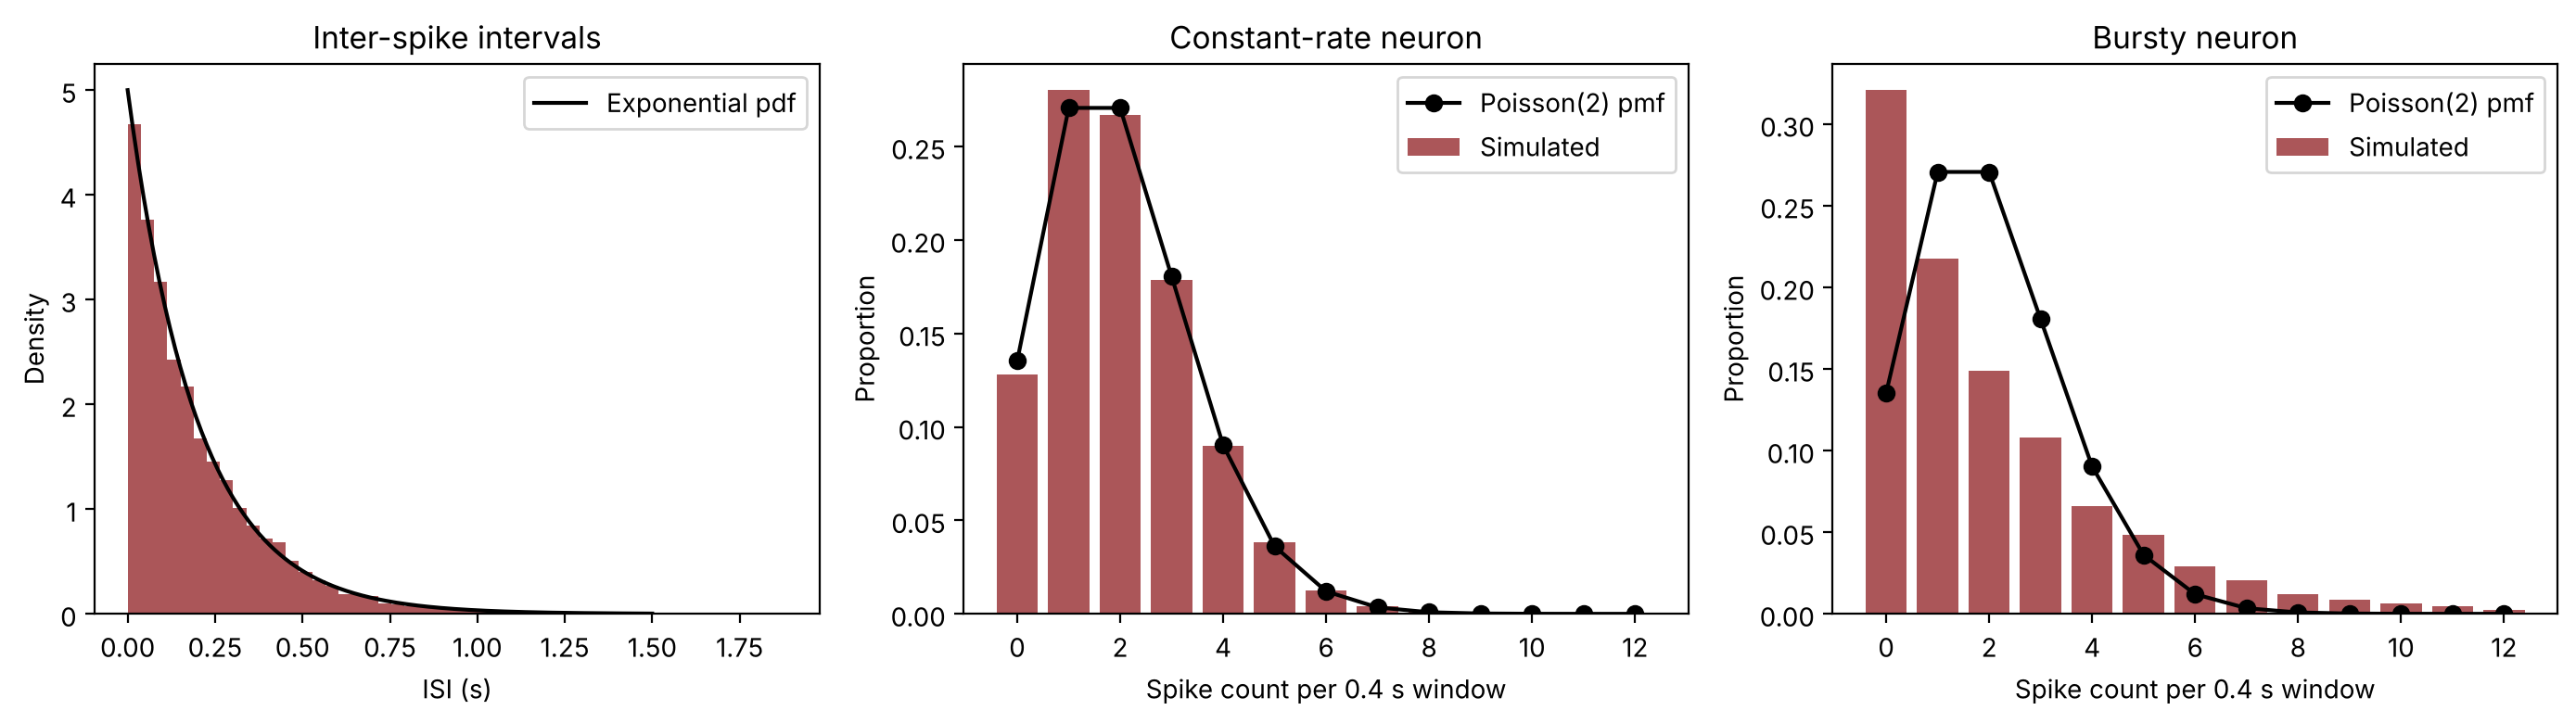

In [4]:
rng = np.random.default_rng(3)

rate = 5.0          # spikes per second
duration = 2000.0   # seconds
window = 0.4        # seconds
lam = rate * window # expected count per window = 2

isis = rng.exponential(scale=1 / rate, size=int(rate * duration * 1.5))
spike_times = np.cumsum(isis)
spike_times = spike_times[spike_times < duration]
isis = np.diff(np.concatenate([[0], spike_times]))

edges = np.linspace(0, duration, int(round(duration / window)) + 1)
counts = np.histogram(spike_times, bins=edges)[0]

print(f"Mean ISI = {isis.mean():.4f} s   (theory 1/rate = {1 / rate:.4f})")
print(f"Var ISI  = {isis.var(ddof=1):.4f} s^2 (theory 1/rate^2 = {1 / rate**2:.4f})")
print(f"Counts: mean = {counts.mean():.3f}, variance = {counts.var(ddof=1):.3f}, "
      f"variance/mean = {counts.var(ddof=1) / counts.mean():.2f}")
print(f"Proportion of empty windows = {np.mean(counts == 0):.3f} (theory e^-2 = {np.exp(-lam):.3f})")

# Bursty neuron: the expected count varies from window to window (mean still 2)
window_rates = rng.gamma(shape=1.0, scale=2.0, size=counts.size)
bursty_counts = rng.poisson(window_rates)
print(f"Bursty counts: mean = {bursty_counts.mean():.3f}, variance = {bursty_counts.var(ddof=1):.3f}, "
      f"variance/mean = {bursty_counts.var(ddof=1) / bursty_counts.mean():.2f}")
print(f"Bursty proportion of empty windows = {np.mean(bursty_counts == 0):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

t_grid = np.linspace(0, 1.5, 200)
axes[0].hist(isis, bins=50, density=True, color="#8f1d21", alpha=0.75)
axes[0].plot(t_grid, rate * np.exp(-rate * t_grid), color="black", label="Exponential pdf")
axes[0].set_title("Inter-spike intervals")
axes[0].set_xlabel("ISI (s)")
axes[0].set_ylabel("Density")
axes[0].legend()

k = np.arange(0, 13)
for ax, data, title in [(axes[1], counts, "Constant-rate neuron"),
                        (axes[2], bursty_counts, "Bursty neuron")]:
    ax.bar(k, [np.mean(data == v) for v in k], color="#8f1d21", alpha=0.75, label="Simulated")
    ax.plot(k, stats.poisson.pmf(k, lam), "ko-", label="Poisson(2) pmf")
    ax.set_title(title)
    ax.set_xlabel("Spike count per 0.4 s window")
    ax.set_ylabel("Proportion")
    ax.legend()

plt.tight_layout()
plt.show()


### Interpretation questions

1. Compare the mean and variance of the ISIs with the exponential predictions.
2. Compare the mean and variance of the window counts. What does the Poisson model predict about their ratio?
3. Compare the proportion of empty windows with $e^{-2}$ from Part 1, Question 5.
4. For the bursty neuron, is a Poisson model appropriate? Use the numbers and the plot.
5. Which simple check would you apply to real spike counts before assuming a Poisson model?


### Model interpretation

1. The mean ISI is about 0.198 s and the variance about 0.039 s², close to $1/\lambda=0.2$ s and $1/\lambda^2=0.04$ s². The histogram follows the exponential density.

2. The counts have mean of about 2.02 and variance of about 2.04, a ratio of about 1.01. A Poisson model predicts mean = variance = $\lambda=2$, so the ratio should be close to 1.

3. About 12.8% of windows are empty, close to $e^{-2}\approx13.5\%$. The small difference is Monte Carlo variability.

4. No. The bursty counts have mean about 2.07 but variance about 6.11 (ratio about 2.95), and about 32% of windows are empty. The variance far exceeds the mean (overdispersion), so the constant-rate assumption fails and the Poisson pmf misfits the plot.

5. Compare the variance with the mean of the counts (the variance-to-mean ratio). This applies the lecture's question "Does the assumed mean–variance relationship fit the data?" For ISIs, check whether the histogram resembles an exponential.
